# Проверка гипотезы в Python на данных сервиса «Яндекс Книги»

## Введение

- Автор: Ивченко Юлия
- Дата: 08.04.2026


Этот проект состоит из нескольких частей. Сначала поработаем с данными сервиса Яндекс Книги, рассчитаем несколько метрик и проверим гипотезу. Затем, уже на других данных, будем анализировать результаты A/B-тестирования.

## Описание данных
Таблицы этого проекта содержат данные о чтении и прослушивании контента в сервисе Яндекс Книги, которые включают информацию о пользователях, платформах, времени, длительности сессий и типах контента. Данные представлены за период с 1 сентября по 11 декабря 2024 года. В вашем распоряжении будет несколько таблиц.

Таблица `bookmate.audition` содержит данные об активности пользователей и состоит из следующих полей:
- `audition_id` — уникальный идентификатор сессии чтения или прослушивания;
- `puid` — идентификатор пользователя;
- `usage_platform_ru` — название платформы, с помощью которой пользователь слушал контент;
- `msk_business_dt_str` — дата события в формате строки (московское время);
- `app_version` — версия приложения, которая использовалась для чтения или прослушивания;
- `adult_content_flg` — был ли это контент для взрослых: True или False;
- `hours` — длительность чтения или прослушивания в часах;
- `hours_sessions_long` — продолжительность длинных сессий чтения или прослушивания в часах;
- `kids_content_flg` — был ли это детский контент: True или False;
- `main_content_id` — идентификатор основного контента;
- `usage_geo_id` — идентификатор географического местоположения.
Таблица `bookmate.content` содержит данные о контенте и состоит из следующих полей:
- `main_content_id` — идентификатор основного контента;
- `main_author_id` — идентификатор основного автора контента;
- `main_content_type` — тип контента;
- `main_content_name`— название контента;
- `main_content_duration_hours` — длительность контента в часах;
- `published_topic_title_list` — список жанров контента.
Таблица `bookmate.author` содержит данные об авторах контента и состоит из следующих полей:
- `main_author_id` — идентификатор основного автора контента;
- `main_author_name` — имя основного автора контента.
Таблица `bookmate.geo` содержит данные о местоположении и состоит из следующих полей:
- `usage_geo_id` — идентификатор географического положения;
- `usage_geo_id_name` — город или регион географического положения;
- `usage_country_name` — страна географического положения.


1. Расчёт MAU авторов
Старший аналитик просит провести анализ и рассчитать ключевые метрики активности пользователей сервиса Яндекс Книги. Цель — глубже понять поведение пользователей и найти примечательные закономерности. Эти расчёты помогут понять, как пользователи взаимодействуют с платформой, какие виды контента наиболее популярны, а также выявить особенности поведения пользователей.



In [ ]:
SELECT main_author_name, count ( DISTINCT puid) as mau
FROM bookmate.audition
LEFT JOIN bookmate.content using(main_content_id)
LEFT JOIN bookmate.author using(main_author_id)
WHERE EXTRACT(MONTH FROM msk_business_dt_str)=11
GROUP BY main_author_name
ORDER BY mau DESC
LIMIT 3;



2. Расчёт MAU произведений
Теперь рассчитайте MAU произведений. Выведите имена топ-3 произведений с наибольшим MAU в ноябре, а также списки жанров этих произведений, их авторов и сами значения MAU.



In [ ]:
SELECT main_content_name, 
        published_topic_title_list, 
        main_author_name, 
        count(DISTINCT puid) as mau 
FROM bookmate.audition
LEFT JOIN bookmate.content USING(main_content_id)
LEFT JOIN bookmate.author USING(main_author_id)
WHERE EXTRACT(MONTH FROM msk_business_dt_str)=11
GROUP BY main_content_name, published_topic_title_list, main_author_name
ORDER BY mau DESC
LIMIT 3;




3. Расчёт Retention Rate
Команда сервиса Яндекс Книги провела рекламную кампанию, которая 2 декабря привлекла множество пользователей. Ваша задача — проанализировать ежедневный Retention Rate всех пользователей, которые были активны 2 декабря. При этом неважно, новые это пользователи или нет, ведь по имеющимся данным этого всё равно не получится определить.


In [ ]:

WITH new_users as
    (SELECT DISTINCT puid
     FROM bookmate.audition
     WHERE CAST(msk_business_dt_str AS DATE)='2024-12-02'),
     active_user as
     (SELECT puid, msk_business_dt_str
     FROM bookmate.audition
     WHERE CAST(msk_business_dt_str AS DATE)>='2024-12-02'),
     daily_retention as
     (SELECT puid, msk_business_dt_str::date-'2024-12-02'::date as day_since_install
     FROM new_users
     LEFT JOIN active_user USING(puid))
SELECT day_since_install, 
       COUNT(DISTINCT puid) as retained_users,
       ROUND(1.0 * COUNT(DISTINCT puid) / MAX(COUNT(DISTINCT puid)) OVER ( ORDER by day_since_install),2) AS  retention_rate
FROM daily_retention
GROUP BY day_since_install
ORDER BY day_since_install;




4. Расчёт LTV
Подписка Яндекс Плюс стоит 399 рублей в месяц. Кроме Яндекс Книг в подписку входят и другие сервисы, однако в рамках этого проекта будем считать, что пользователь приносит 399 рублей, если хотя бы раз в месяц пользуется Яндекс Книгами. При этом потенциально платящих, но неактивных пользователей не нужно учитывать.
По имеющимся данным рассчитайте средние LTV, за все время, для пользователей в Москве и Санкт-Петербурге и сравните их между собой.


In [ ]:

WITH activ_user as (
    SELECT usage_geo_id_name as city, puid as activr_puid, 
            399*count (DISTINCT EXTRACT(MONTH FROM msk_business_dt_str)) as profit
    FROM bookmate.audition
    LEFT JOIN bookmate.geo USING(usage_geo_id)
    WHERE usage_geo_id_name='Москва' or usage_geo_id_name='Санкт-Петербург'
    GROUP BY city, puid
),
    sum_activ_user as(
    SELECT city, SUM(profit) as all_profit
    FROM activ_user
    GROUP BY city
),
    all_user as (
    SELECT usage_geo_id_name as city, count(DISTINCT puid) AS total_users
    FROM bookmate.audition
    LEFT JOIN bookmate.geo USING(usage_geo_id)
    WHERE usage_geo_id_name='Москва' or usage_geo_id_name='Санкт-Петербург'
    GROUP BY city    
)
SELECT city, 
        total_users, 
        ROUND(all_profit/total_users,2) as ltv
FROM sum_activ_user
LEFT JOIN all_user USING(city);





5. Расчёт средней выручки прослушанного часа — аналог среднего чека
Как мы уже говорили, предполагается, что в сервисе используется модель монетизации с единой подпиской. По этой причине рассчитывать средний чек транзакций нецелесообразно, ведь он будет равен стоимости подписки. Тем не менее можно рассчитать ежемесячную среднюю выручку от часа чтения или прослушивания по такой формуле: выручка (MAU * 399 рублей) / сумма прослушанных часов.
Рассчитайте эту метрику вместе с MAU и суммой прослушанных часов с сентября по ноябрь.


In [ ]:

WITH a as(
    SELECT DATE_TRUNC('month', CAST(msk_business_dt_str AS DATE))::DATE as month, 
        COUNT(DISTINCT puid) as mau, 
        ROUND(SUM(hours)::numeric,2) as hours
    FROM bookmate.audition
    WHERE (EXTRACT(MONTH FROM msk_business_dt_str) BETWEEN 9 AND 11)
    GROUP BY month)
SELECT month, mau, hours, ROUND(AVG(399* mau/hours), 2) as avg_hour_rev
FROM a
GROUP BY month, mau, hours
ORDER BY month;



В SQL мы предобработали данные и нашли основные метрики: MAU авторов, MAU произведений, Retention Rate, LTV и средняя выручка прослушанного часа — аналог среднего чека. И теперь данные готовы для проверки гипотезы в Python. Команда сервиса Яндекс Книги изучила данные, полученные при анализе LTV, и выдвинула гипотезу. Она заключается в том, что пользователи, которые приносят больший LTV, являются более лояльными, а значит, проводят в среднем больше времени за чтением и прослушиванием книг в приложении. Нужно сравнить пользователей из Санкт-Петербурга и Москвы, ведь при расчётах среднего LTV было определено, что эта метрика у петербуржцев выше.

Для начала с помощью SQL приведите исходные данные из таблиц к такому виду, который будет пригодным для проверки гипотезы в Python. Отберите пользователей только из Москвы и Санкт-Петербурга и выведите их активность, то есть сумму часов.


In [ ]:
SELECT usage_geo_id_name as city, puid, SUM(hours) as hours
FROM bookmate.audition
LEFT JOIN bookmate.geo USING(usage_geo_id)
WHERE usage_geo_id_name='Москва' or usage_geo_id_name='Санкт-Петербург'
GROUP BY usage_geo_id_name, puid;

## Цели и задачи проекта


**Цель**: проверить гипотезу о том, что пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении по сравнению с пользователями из Москвы.


**Задачи:**
1. Загрузить данные.
2. Провести предобработку данных (а именно: проверить наличие дубликатов в идентификаторах пользователей, сравнить размеры групп, их статистики и распределение).
3. Статистически доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

4. По результатам анализа данных подготовить аналитическую записку.

## Описание данных

Таблица `yandex_knigi_data` содержит данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности.


* `city` — город пользователя;
* `puid` — идентификатор пользователя;
* `hours` — общее количество часов активности;

## Содержимое проекта

1. Введение.
2. Цели и задачи.
3. Описание данных.
4. Загрузка данных и знакомство с ними.
5. Проверка гипотезы.
6. Аналитическая записка.

## 1. Загрузка данных и знакомство с ними
Начнём с загрузки библиотек.

Загрузим данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `path_yandex_knigi_data.csv` и выведем первые строки на экран.

In [1]:
# Импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# Выгружаем данные в переменную df
df = pd.read_csv('path_yandex_knigi_data', index_col=0)
# Выводим первые строки датафрейма df на экран и количество строк 
df_shape=df.shape[0]
display(df.head())
display(df_shape)

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


8784

В датафрейме определим количество пропусков и дубликатов в идентификаторах пользователей. Это необходимо для понимания полноты и уникальности данных пользователей. 

In [3]:
# определяем количество пропусков и дубликатов
display(df['puid'].isna().sum(), df.duplicated(subset='puid', keep=False).sum())

np.int64(0)

np.int64(488)

У нас в индетификаторах пользователей имеются дубликаты. Проверим их

In [4]:
df[df.duplicated(subset='puid', keep=False)].sort_values(by='puid')

,city,puid,hours
35,Москва,2637041,10.317371
6247,Санкт-Петербург,2637041,3.883926
134,Москва,9979490,32.415573
6274,Санкт-Петербург,9979490,1.302997
145,Москва,10597984,42.931506
...,...,...,...
6195,Москва,1130000020425037,0.310556
8775,Санкт-Петербург,1130000023864516,14.384722
6202,Москва,1130000023864516,142.830085
6210,Москва,1130000028554332,11.277554


Видим, что один и тот же пользователь имеет 2 записи в 2х городах одновременно. Чтобы не искажать результаты исследования, удалим этих пользователей

In [5]:
df=df.drop_duplicates(subset='puid', keep=False)
display(df.shape[0])

8296

In [6]:
# определяем количество пользователей в городах
df.groupby('city')['puid'].count()

city
Москва             5990
Санкт-Петербург    2306
Name: puid, dtype: int64

В Москве количество пользователей Яндекс Книги больше в 2,5 раза, чем в Санкт-Петербурге.

Сравним основные показатели для пользователей в Москве и Санкт-Петербурге

In [7]:
# находим статистику
mosk_stats = df[df['city'] == 'Москва']['hours'].describe()
speter_stats = df[df['city'] == 'Санкт-Петербург']['hours'].describe()

display("Пользователи в Мосвке:", mosk_stats)
display("Пользователи в Санкт-Петербурге:", speter_stats)

'Пользователи в Мосвке:'

count    5990.000000
mean       10.848192
std        36.925622
min         0.000022
25%         0.057042
50%         0.888232
75%         5.933439
max       857.209373
Name: hours, dtype: float64

'Пользователи в Санкт-Петербурге:'

count    2306.000000
mean       11.264433
std        39.831755
min         0.000025
25%         0.060173
50%         0.875355
75%         6.138424
max       978.764775
Name: hours, dtype: float64

Средняя сумма часов прослушивания для пользователей в Москве (10,8) и для пользователей в Санкт-Петербурге (11,2) примерно одинаковая, для Санкт-Петербурга чуть выше. Стандартное отклонение довольно высокое и в одной и в другой группе - 36,9 и 39,8 соответственно, это указывает, что данные могут иметь широкий разброс. Максимальное время прослушивания - 857 и 978 часов соответственно. 

Дополнительно проверим это и построим диаграмму размаха.

<Figure size 1000x200 with 0 Axes>

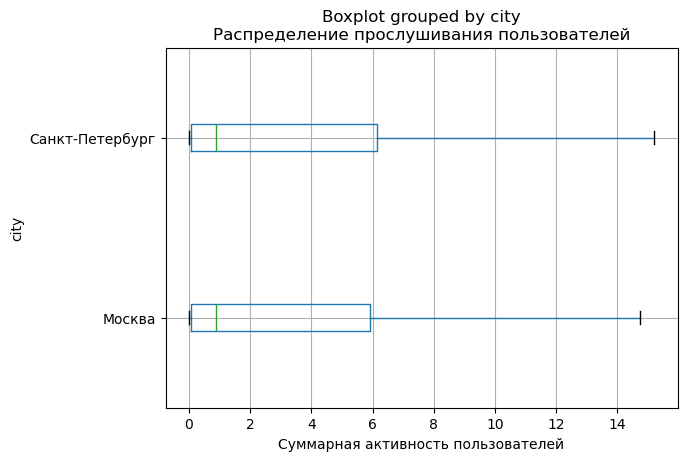

In [8]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 2))

# Строим диаграмму размаха значений
df.boxplot(column='hours', by='city', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение прослушивания пользователей')
plt.xlabel('Суммарная активность пользователей')

# Выводим график
plt.show()

Распределение данных выглядит ассиметриячным и характеризуется широким разбросом и «хвостом» в правой части гистограммы.

Определим пользователей с аномальным прослушиваний Яндекс Книг.

Для каждой группы посчитаем верхнюю границу, нижняя граница равна 0, а минимальное значение больше 0, поэтому проверяем значения только по верхней границе, и потом исключим из датасета пользователей, у которых аномальная длительность прослушивания.

In [9]:
#определим для каждого сегмента верхнюю границу
df['upper_limit'] = df.groupby('city')['hours'].transform(lambda x: 
                                                    x.quantile(0.75) + 1.5 * (x.quantile(0.75) - x.quantile(0.25)))
#создадим столбец, в котором - если значение общего объема финансирования выходит за верхнюю границу, то будет True
df['anomal'] = df['upper_limit'] < df['hours']
#исключим из датафрейма аномальные значения
df=df[df['anomal']==False]
# определяем количество пользователей в городах после исключения аномальных значений
df.groupby('city')['puid'].count()

city
Москва             5124
Санкт-Петербург    1960
Name: puid, dtype: int64

Построим гистограмму распределения длительности прослушивания пользователей по городам.

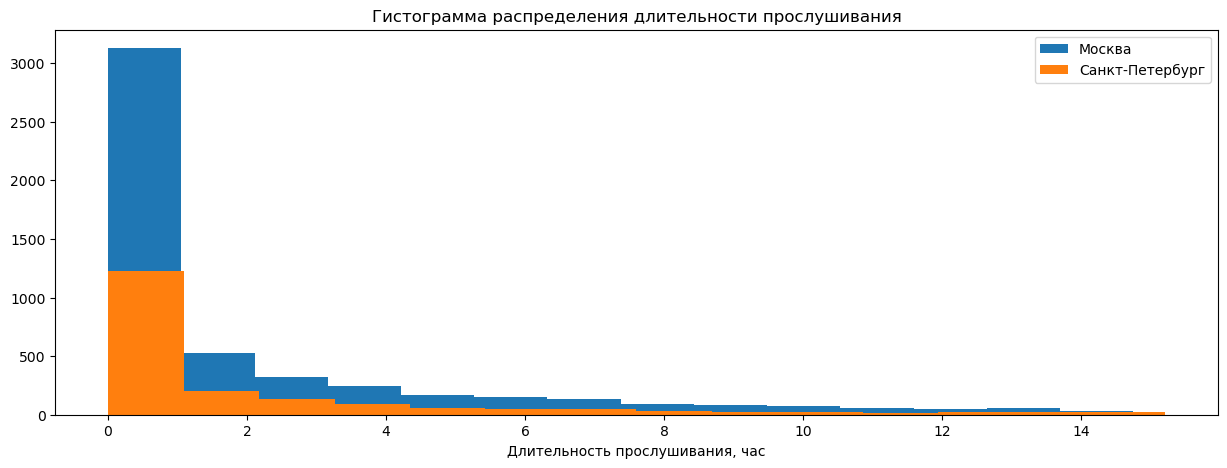

In [10]:
# Гистограмма длительности поездки для пользователей с подпиской и без
plt.figure(figsize=(15, 5))

plt.hist(df[df['city'] == 'Москва']['hours'], bins=14, label='Москва')
plt.hist(df[df['city'] == 'Санкт-Петербург']['hours'], bins=14, label='Санкт-Петербург')
plt.legend()
plt.title('Гистограмма распределения длительности прослушивания')
plt.xlabel('Длительность прослушивания, час')

plt.show()



Как видим, распределение пользователей в Москве и в Санкт-Петербурге одинаковое: ассиметричное, правосторонеее. Максимальное количество пользователей слушают Яндекс Книги - час. 

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуем статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

In [11]:
# Данные о 2х группах
mosk_df=df[df['city'] == 'Москва']['hours'] 
speter_df=df[df['city'] == 'Санкт-Петербург']['hours']
# Уровень статистической значимости:
alpha=0.05

results = st.ttest_ind (mosk_df, speter_df, alternative='less' ) # Альтернативная гипотеза, которую проверяем: mu1 < mu2
p_value =results.pvalue
if p_value<alpha:
    display(f'Полученное значение p_value={round(p_value,2)} меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.')
else:
    display(f'Полученное значение p_value={round(p_value,2)} больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.')

'Полученное значение p_value=0.55 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.'

Так как не опровергаем нулевую гипотезу, то средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

## 3. Аналитическая записка

Для проверки гипотезы о равенстве средних двух выборок (средняя активность пользователей в Москве и средняя активность пользователей в Санкт-Петербурге) используется t-test, а именно — его двухвыборочный аналог. Все условия для применения t-теста Стьюдента выполняются, а именно выборочное среднее распределено нормально, значения в выборках независимые и одинаково распределённые.
Уровень статистической значимости был выбран α = 0,05, как стандартный в большинстве прикладных исследований. Он обеспечивает разумный баланс и ограничивает вероятность ложноположительного результата (ошибки I рода) до 5 %.

Полученное значение p_value=0.55.  Р_value больше критического уровня alpha=0.05, значит мы не смогли отвергнуть нулевую гипотезу в пользу альтернативной, а это значит следующее: средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

Возможные причины, объясняющие полученные результаты:
- Отсутствие статистически значимых различий в активности пользователей. Возможно, у пользователей в Москве и Санкт-Петербурге сходжий характер к прослушиванию Яндекс Книг.
- Недостаточная мощность теста. Хотя все условия для применения t-теста Стьюдента выполняются, возможно, размер выборок недостаточно велик, чтобы обнаружить небольшие различия в средней активности пользователей, если они всё же присутствуют. В этом случае даже реальные различия могут не достигать статистической значимости при выбранном уровне α = 0,05.


----

# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



Цель: проверить гипотезу о том, что с новым интерфейом увеличится конверсия покупок.

Задачи:

- Загрузить данные.
- Оценить корректность проведения теста
- Рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

## 2. Загрузите данные, оцените их целостность.


Сохраним в датафрейм participants и events CSV-файл с данными о сессиях пользователей ab_test_participants.csv. и ab_test_events.zip соответственно.

In [12]:
# Выгружаем данные в переменную sessions_test_part
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip', parse_dates=['event_dt'], low_memory=False)
# Выгружаем на экран первые 5 строк
display(participants)
display(events)

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac
...,...,...,...,...
14520,FFE7FC140521F5F6,A,interface_eu_test,PC
14521,FFEFC0E55C1CCD4F,A,interface_eu_test,PC
14522,FFF28D02B1EACBE1,B,recommender_system_test,PC
14523,FFF28D02B1EACBE1,B,interface_eu_test,PC


,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN
...,...,...,...,...
787281,1A655C280B064708,2020-12-31 23:57:44,product_page,NaN
787282,B77B2F4BCA134618,2020-12-31 23:58:23,registration,0.0
787283,GLOBAL,2020-12-31 23:58:30,product_cart,NaN
787284,B12AD1623E494FAD,2020-12-31 23:58:34,registration,-6.52


## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделим пользователей, участвующих в тесте, и проверим:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [13]:
# из датафрейма берем данные только с АВ - теста 'interface_eu_test'
participants=participants[participants['ab_test']=='interface_eu_test']
display(participants)

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
2,001064FEAAB631A1,A,interface_eu_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac
5,002412F1EB3F6E38,B,interface_eu_test,Mac
6,002540BE89C930FB,B,interface_eu_test,Android
...,...,...,...,...
14519,FFE600EEC4BA7685,B,interface_eu_test,Android
14520,FFE7FC140521F5F6,A,interface_eu_test,PC
14521,FFEFC0E55C1CCD4F,A,interface_eu_test,PC
14523,FFF28D02B1EACBE1,B,interface_eu_test,PC


Рассчитаем количество уникальных пользователей в каждой из экспериментальных групп.

In [14]:
# расчитаем кол-во уникальных пользователей и их долю
test_count=participants.groupby('group')['user_id'].nunique()
test_doly=test_count/test_count.sum()
display(test_count)
display(test_doly)

group
A    5383
B    5467
Name: user_id, dtype: int64

group
A    0.496129
B    0.503871
Name: user_id, dtype: float64

Рассчитаем и выведем на экран процентную разницу в количестве пользователей в группах A и B. 

Для расчёта процентной разницы воспользуйемся формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [15]:
# расчитаем процентную разницу 
round((test_count['A']-test_count['B'])/test_count['A']*100,2)

np.float64(-1.56)

Разница в численности групп A и B составила 1.5%, что находится в пределах допустимого и не искажает результаты A/B‑теста.

Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

Рассчитаем количество пользователей, которые встречаются одновременно в группах A и B.

In [16]:
A = participants[participants['group'] == 'A']['user_id']
B = participants[participants['group'] == 'B']['user_id']

intersection = list(set(A) & set(B))
display(intersection) 

[]

Убедились, что пользователи не пересекаются и группы независимы.

3\.2 Проанализируем данные о пользовательской активности по таблице `ab_test_events`:

Содеиним 2 таблицы, и оставим только пользователей, которые учавствуют в АВ- тесте по изменению интерфейса.

In [17]:
# соединяем датафреймы
df=participants.merge(events, on='user_id', how='left')
display(df)

,user_id,group,ab_test,device,event_dt,event_name,details
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38
1,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:49,login,NaN
2,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:57,login,NaN
3,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:38:54,login,NaN
4,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-08 22:15:35,login,NaN
...,...,...,...,...,...,...,...
79710,FFF28D02B1EACBE1,B,interface_eu_test,PC,2020-12-24 00:56:12,product_cart,NaN
79711,FFF28D02B1EACBE1,B,interface_eu_test,PC,2020-12-24 00:57:23,product_cart,NaN
79712,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:37:34,registration,-0.45
79713,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:56:02,login,NaN


- определим горизонт анализа: рассчитаем время (лайфтайм) совершения события пользователем после регистрации и оставим только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [18]:
# добавляем столбец registration
df_registration=df[df['event_name']=='registration'][['user_id','event_dt']].rename(columns={'event_dt': 'registration'})
df=df.merge(df_registration, on='user_id', how='left')
display(df)

,user_id,group,ab_test,device,event_dt,event_name,details,registration
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38,2020-12-07 04:37:31
1,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:49,login,NaN,2020-12-07 04:37:31
2,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:57,login,NaN,2020-12-07 04:37:31
3,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:38:54,login,NaN,2020-12-07 04:37:31
4,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-08 22:15:35,login,NaN,2020-12-07 04:37:31
...,...,...,...,...,...,...,...,...
79710,FFF28D02B1EACBE1,B,interface_eu_test,PC,2020-12-24 00:56:12,product_cart,NaN,2020-12-16 08:23:56
79711,FFF28D02B1EACBE1,B,interface_eu_test,PC,2020-12-24 00:57:23,product_cart,NaN,2020-12-16 08:23:56
79712,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:37:34,registration,-0.45,2020-12-13 17:37:34
79713,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:56:02,login,NaN,2020-12-13 17:37:34


In [19]:
# отфильтровываем данные только первые 7 дней после регистрации
df=df[(df['event_dt']-df['registration'])<=pd.Timedelta(days=7)]
display(df)

,user_id,group,ab_test,device,event_dt,event_name,details,registration
0,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:31,registration,-2.38,2020-12-07 04:37:31
1,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:49,login,NaN,2020-12-07 04:37:31
2,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:37:57,login,NaN,2020-12-07 04:37:31
3,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-07 04:38:54,login,NaN,2020-12-07 04:37:31
4,0002CE61FF2C4011,B,interface_eu_test,Mac,2020-12-08 22:15:35,login,NaN,2020-12-07 04:37:31
...,...,...,...,...,...,...,...,...
79707,FFF28D02B1EACBE1,B,interface_eu_test,PC,2020-12-21 15:22:59,product_page,NaN,2020-12-16 08:23:56
79708,FFF28D02B1EACBE1,B,interface_eu_test,PC,2020-12-21 15:24:00,product_page,NaN,2020-12-16 08:23:56
79712,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:37:34,registration,-0.45,2020-12-13 17:37:34
79713,FFF58BC33966EB51,A,interface_eu_test,Android,2020-12-13 17:56:02,login,NaN,2020-12-13 17:37:34


Оценим достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

- Минимальный детектируемый эффект, или MDE, будем считать равноым 3%.

In [20]:

# Задайте параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p1 = 0.3 # Базовый уровень доли
mde = p1*0.03 # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p1, p1 + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size ,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


Рассчитаем для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [21]:
# нахоодим какие операции могут совершать пользователи
df['event_name'].unique()

array(['registration', 'login', 'product_page', 'product_cart',
       'purchase'], dtype=object)

In [22]:
#находим кол-во посетителей, совершивших покупкук
df1=df[df['event_name']=='purchase'].groupby('group', as_index=False).agg(count_purchase=('user_id', 'nunique'))
#находим количество посетителей
df2=df.groupby('group', as_index=False).agg(count_all=('user_id', 'nunique'))
df_count=df1.merge(df2, on='group')
df_count['cr']=round(df_count['count_purchase']/df_count['count_all'] , 2)
display(df_count)

,group,count_purchase,count_all,cr
0,A,1480,5383,0.27
1,B,1600,5467,0.29


In [23]:
#находим разницу между коннверсией
diff = df_count.loc[df_count['group'] == 'B', 'cr'].values[0] - df_count.loc[df_count['group'] == 'A', 'cr'].values[0]
display(f'Разница между конверсией покупок посетителей А и В составляет: {round(diff * 100, 1)}%')

'Разница между конверсией покупок посетителей А и В составляет: 2.0%'

Визуализируем конверсию покупок посетителей

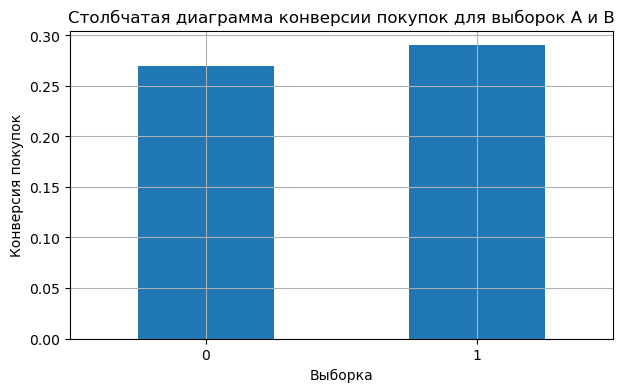

In [24]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 4))

# Строим гистограмму с помощью pandas через plot(kind='bar')
df_count['cr'].plot(
               kind='bar', # Тип графика - столбчатая диаграмма
               rot=0, # Градус вращения подписи по оси Х
               title=f'Столбчатая диаграмма конверсии покупок для выборок А и В',
                legend=False
)
# Настраиваем оформление графика
plt.xlabel('Выборка')
plt.ylabel('Конверсия покупок')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Количество посетителей, совершивших покупку, и общее количество посетителей в группе В увеличилось. Конверсия в группе В тоже увеличилась на 0,02. В группе А конверсия 0,27, в группе В - 0,29.

## 4. Проведите оценку результатов A/B-тестирования:

Ключевая метрика - конверсия покупок пользователей.

Сформулируем нулевую и альтернативную гипотезы: 
- Н0: новый интерфейс не влияет на конверсия покупок пользователей CR_A=CR_B
- Н1: новый интерфейс увеличивает конверсию покупок пользователей CR_A<CR_B

На предыдущем шаге мы убедились, что конверсия покупок посетителей в тестовой группе примерно на 2% выше, чем в контрольной, но делать выводы только на основе этого значения будет некорректно. Для принятия решения необходимо ответить на вопрос: является ли это изменение статистически значимым.

Используя статистический тест, рассчитаем, является ли изменение в метрике конверсии покупок статистически значимым. Используем z-тест пропорций.

Выведим на экран полученное значение p-value и свои выводы о статистической значимости. Напомним, что уровень значимости в эксперименте был выбран на уровне 0.05.

In [25]:
# проверим, выполняется ли предпосылка Z-теста пропорций о достаточном размере выборок
n_a, n_b = df[df.group=='A'].shape[0], df[df.group=='B'].shape[0] ## размеры выборок A и B
m_a = df[(df.group=='A')&(df['event_name']=='purchase')].shape[0] # количество успехов (регистраций) в группе A
m_b = df[(df.group=='B')&(df['event_name']=='purchase')].shape[0] # количество успехов (регистраций) в группе B

p_a, p_b = m_a/n_a, m_b/n_b # рассчитываем доли успехов для каждой группы: A и B
print(f'n_a={n_a}, n_b={n_b}')
print(f'm_a={m_a}, m_b={m_b}')
print(f'p_a={p_a}, p_b={p_b}')

if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10):
    print('Предпосылка о достаточном количестве данных выполняется!')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется!')

n_a=33762, n_b=35187
m_a=2895, m_b=3728
p_a=0.0857472898524969, p_b=0.10594821951288828
Предпосылка о достаточном количестве данных выполняется!


In [26]:
# Проводим Z-тест пропорций
alpha = 0.05 # На каком уровне значимости проверяем гипотезу о равенстве вероятностей

stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller' # так как H_1: p_a < p_b
)
p_value_ztest

if p_value_ztest > alpha:
    print(f'pvalue={p_value_ztest} > {alpha}')
    print('Нулевая гипотеза находит подтверждение!')
else:
    print(f'pvalue={p_value_ztest} < {alpha}')
    print('Нулевая гипотеза не находит подтверждения!')

pvalue=1.14229635923504e-19 < 0.05
Нулевая гипотеза не находит подтверждения!


Значение p-value оказалось близким к нулю, поэтому нет оснований принимать нулевую гипотезу. Это означает, что существует статистически значимое различие между конверсиями покупок пользователей в группах A и B. Поскольку альтернативная гипотеза утверждала, что новый интерфейс увеличивает конверсию покупок пользователей, результаты подтверждают это предположение. Действительно, команда разработчиков улучшила интерфейс, который показывает более интересный контент для каждого пользователя.

Выводы:

-С изменением интерфейса ключевая метрика - конверсия покупок посетителей увеличилась на 2%. Чтобы узнать является ли это изменение статистически значимым - использовали z-тест пропорций.

-Значение p-value оказалось близким к нулю, значит нулевая гипотеза не находит подтверждение. Значит, действительно, интерфейс онлайн-магазина стал понятнее для пользователей.

-Внедрять новый интерфейс стоит, и это подтверждено тестом.